# Project 3: Word Embeddings with TF-IDF and PCA

Dataset: AG News (news articles in four categories). Each article is turned into a TF-IDF vector, and PCA, written from scratch, then reduces those vectors to a small number of dimensions while keeping as much variance as possible.

In [1]:
import html
import re
import ssl

import certifi
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from collections import Counter

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.edgecolor": "#999999", "axes.titleweight": "bold",
})
pd.set_option("display.max_colwidth", None)

## 1. Load the data

Load the training set and take a balanced random sample of 1,000 articles per category. Each document is the article's title plus its description.

In [2]:
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]
PER_CLASS = 1000

news = pd.read_csv("data/ag_news_csv/train.csv", header=None, names=["label", "title", "description"])
news["category"] = news["label"].map(lambda i: CLASSES[i - 1])
sample = (news.groupby("category", group_keys=False)
              .sample(PER_CLASS, random_state=42)
              .reset_index(drop=True))
sample["text"] = sample["title"] + " " + sample["description"]

print(f"{len(sample):,} articles")
sample[["category", "text"]].head()

4,000 articles


,category,text
0,Business,US house sales fall in July Sales of non-new houses in the US fell last month but still exceeded analyst forecasts.
1,Business,"DJ to acquire MarketWatch Dow Jones amp; Co., publisher of the Wall Street Journal, says it has agreed to buy online news site MarketWatch Inc. in a \$519 million deal that widens its Internet audience."
2,Business,"Dollar hits new low on Snow speech The United States supports a quot;strong dollar, quot; Treasury Secretary John Snow said, while suggesting the Bush administration will not act to boost its value. His comments sent the currency plunging to a record low against the euro."
3,Business,Yukos executives 'flee' Russia All the top executives at Russian oil giant Yukos have fled the country in fear of arrest as the government seeks to sell off its main asset.
4,Business,"Smithfield quarterly profits beat outlook SMITHFIELD, Va. Meat processor Smithfield Foods says its income more than doubled in the most recent quarter. The company cites improved profitability in the hog production segment, combined with strong results"


## 2. Clean and tokenize

Fix the HTML leftovers in the raw text, lower-case it, keep only words, and remove stopwords and news-agency tags ("reuters", "ap").

In [3]:
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words("english")) | {"reuters", "ap", "afp", "quot", "said"}
WORD = re.compile(r"[a-z]+(?:'[a-z]+)*")


def tokenize(text):
    # the raw text has HTML entities with the "&" missing ("#39;", "amp;"): restore it, then decode
    text = re.sub(r"(?<!&)(#\d+|\bamp|\bquot|\blt|\bgt);", r"&\1;", text)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>|https?://\S+|\\", " ", text)   # html tags, links, stray backslashes
    text = text.replace("’", "'").lower()
    text = re.sub(r"\bu\.s\.", "usa", text)                 # keep "U.S." as one word
    return [t for t in WORD.findall(text) if len(t) > 1 and t not in STOPWORDS]


docs = [tokenize(t) for t in sample["text"]]
labels = sample["category"].to_numpy()
print(sample["text"][0], "\n->", docs[0])

US house sales fall in July Sales of non-new houses in the US fell last month but still exceeded analyst forecasts. 
-> ['us', 'house', 'sales', 'fall', 'july', 'sales', 'non', 'new', 'houses', 'us', 'fell', 'last', 'month', 'still', 'exceeded', 'analyst', 'forecasts']


## 3. TF-IDF vectors

Each document becomes a vector with one entry per vocabulary word. The entry is the word's count (TF) times $\text{idf}(w) = \ln\frac{1+N}{1+\text{df}(w)} + 1$, which down-weights words found in many documents. Each row is then scaled to length 1. The vocabulary is the 2,000 most frequent words that occur in at least 5 documents.

In [4]:
VOCAB_SIZE, MIN_DF = 2000, 5
doc_freq = Counter(w for d in docs for w in set(d))
term_freq = Counter(w for d in docs for w in d)
vocab = [w for w, _ in term_freq.most_common() if doc_freq[w] >= MIN_DF][:VOCAB_SIZE]


def tfidf(docs, vocab):
    index = {w: j for j, w in enumerate(vocab)}
    N = len(docs)
    tf = np.zeros((N, len(vocab)))
    for i, d in enumerate(docs):
        for t in d:
            if t in index:
                tf[i, index[t]] += 1
    df = (tf > 0).sum(axis=0)
    idf = np.log((1 + N) / (1 + df)) + 1
    X = tf * idf
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    norms[norms == 0] = 1
    return X / norms


X = tfidf(docs, vocab)
print(f"X: {X.shape[0]:,} documents x {X.shape[1]:,} words")

# check against scikit-learn
from sklearn.feature_extraction.text import TfidfVectorizer
assert np.allclose(TfidfVectorizer(vocabulary=vocab, analyzer=lambda d: d).fit_transform(docs).toarray(), X)
print("matches scikit-learn's TfidfVectorizer")

X: 4,000 documents x 2,000 words


matches scikit-learn's TfidfVectorizer


## 4. PCA from scratch

```
μ  ← mean of each column of X
Xc ← X − μ                              # center
C  ← Xcᵀ Xc / (n − 1)                   # covariance matrix (p × p)
λ, V ← eigenvalues/eigenvectors of C, sorted largest first
W  ← first k columns of V
Z  ← Xc W                               # reduced data (n × k)
```

### Step 1: mean and centering

Compute each feature's mean and subtract it, so every column has mean 0.

In [5]:
n, p = X.shape
mu = X.mean(axis=0)
Xc = X - mu

assert np.allclose(Xc.mean(axis=0), 0)
print("highest-mean words:", ", ".join(pd.Series(mu, index=vocab).nlargest(8).index))
print(f"max |column mean| after centering: {np.abs(Xc.mean(axis=0)).max():.1e}")

highest-mean words: new, us, first, two, year, one, world, oil
max |column mean| after centering: 2.3e-16


### Step 2: covariance matrix

$C = X_c^\top X_c / (n-1)$. Entry $C_{ab}$ is positive when words $a$ and $b$ tend to appear in the same documents, and negative when they rarely do.

In [6]:
C = Xc.T @ Xc / (n - 1)

assert np.allclose(C, C.T) and np.allclose(C, np.cov(X, rowvar=False))
print(f"C: {C.shape[0]:,} x {C.shape[1]:,}, symmetric, matches np.cov")

show = ["game", "season", "oil", "prices", "software", "microsoft", "iraq"]
idx = [vocab.index(w) for w in show]
pd.DataFrame(C[np.ix_(idx, idx)] * 1e4, index=show, columns=show).style.format("{:.2f}").set_caption(
    "Covariance between selected words (x 10^4)")

C: 2,000 x 2,000, symmetric, matches np.cov


,game,season,oil,prices,software,microsoft,iraq
game,22.04,0.79,-0.86,-0.42,-0.27,-0.32,-0.62
season,0.79,16.25,-0.66,-0.46,-0.27,-0.43,-0.59
oil,-0.86,-0.66,28.04,12.73,-0.54,-0.77,0.21
prices,-0.42,-0.46,12.73,15.39,-0.36,-0.54,-0.10
software,-0.27,-0.27,-0.54,-0.36,17.14,4.82,-0.60
microsoft,-0.32,-0.43,-0.77,-0.54,4.82,25.37,-0.70
iraq,-0.62,-0.59,0.21,-0.10,-0.60,-0.70,23.01


### Step 3: sorted eigenvalues and eigenvectors

`np.linalg.eigh` (for symmetric matrices) returns eigenvalues in ascending order, so they are reversed to put the largest first. Each eigenvalue is the variance along its eigenvector.

In [7]:
eigvals, eigvecs = np.linalg.eigh(C)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = np.clip(eigvals[order], 0, None), eigvecs[:, order]

assert np.all(np.diff(eigvals) <= 0)                                   # sorted
assert np.allclose(eigvecs.T @ eigvecs, np.eye(p))                     # orthonormal
assert np.allclose(C @ eigvecs[:, :5], eigvecs[:, :5] * eigvals[:5])   # C v = λ v

explained = eigvals / eigvals.sum()
cumulative = np.cumsum(explained)
pd.DataFrame({"eigenvalue": eigvals[:10], "variance explained": explained[:10], "cumulative": cumulative[:10]},
             index=pd.RangeIndex(1, 11, name="component")).style.format(
    {"eigenvalue": "{:.5f}", "variance explained": "{:.2%}", "cumulative": "{:.2%}"})

,eigenvalue,variance explained,cumulative
component,,,
1,0.00600,0.61%,0.61%
2,0.00514,0.52%,1.13%
3,0.00493,0.50%,1.62%
4,0.00400,0.40%,2.03%
5,0.00387,0.39%,2.42%
6,0.00346,0.35%,2.77%
7,0.00334,0.34%,3.11%
8,0.00321,0.32%,3.43%
9,0.00315,0.32%,3.75%


### Step 4: choose k and project

Keep the top $k$ eigenvectors and project the centered data onto them.

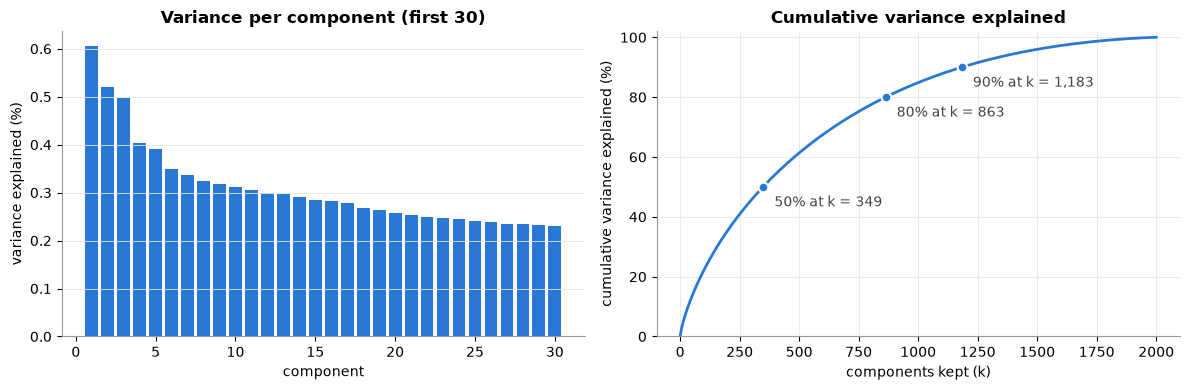

In [8]:
k_for = {t: int(np.searchsorted(cumulative, t) + 1) for t in (0.5, 0.8, 0.9)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(np.arange(1, 31), explained[:30] * 100, color="#2a78d6", width=0.8)
ax1.set(xlabel="component", ylabel="variance explained (%)", title="Variance per component (first 30)")
ax1.grid(axis="x", visible=False)

ax2.plot(np.arange(1, p + 1), cumulative * 100, color="#2a78d6", lw=2)
for t, k in k_for.items():
    ax2.plot(k, t * 100, "o", ms=7, color="#2a78d6", mec="white", mew=1.5)
    ax2.annotate(f"{t:.0%} at k = {k:,}", (k, t * 100), xytext=(8, -14), textcoords="offset points", color="#444444")
ax2.set(xlabel="components kept (k)", ylabel="cumulative variance explained (%)",
        title="Cumulative variance explained", ylim=(0, 102))
plt.tight_layout()
plt.show()

In [9]:
K = 100
W = eigvecs[:, :K]
Z = Xc @ W
print(f"{X.shape} -> {Z.shape}, keeping {cumulative[K - 1]:.1%} of the variance")

# checks: variance along each component = its eigenvalue; lost variance = sum of dropped eigenvalues;
# result matches scikit-learn's PCA (eigenvectors only defined up to sign)
assert np.allclose(Z.var(axis=0, ddof=1), eigvals[:K])
assert np.isclose(((Xc - Z @ W.T) ** 2).sum() / (n - 1), eigvals[K:].sum())
from sklearn.decomposition import PCA
sk = PCA(n_components=K, svd_solver="full").fit(X)
assert np.allclose(sk.explained_variance_, eigvals[:K])
assert np.allclose(np.abs(np.sum(sk.components_ * W.T, axis=1)), 1)
print("all checks pass, matches scikit-learn's PCA")

(4000, 2000) -> (4000, 100), keeping 22.2% of the variance


all checks pass, matches scikit-learn's PCA


## 5. Results

### Documents in the first two components

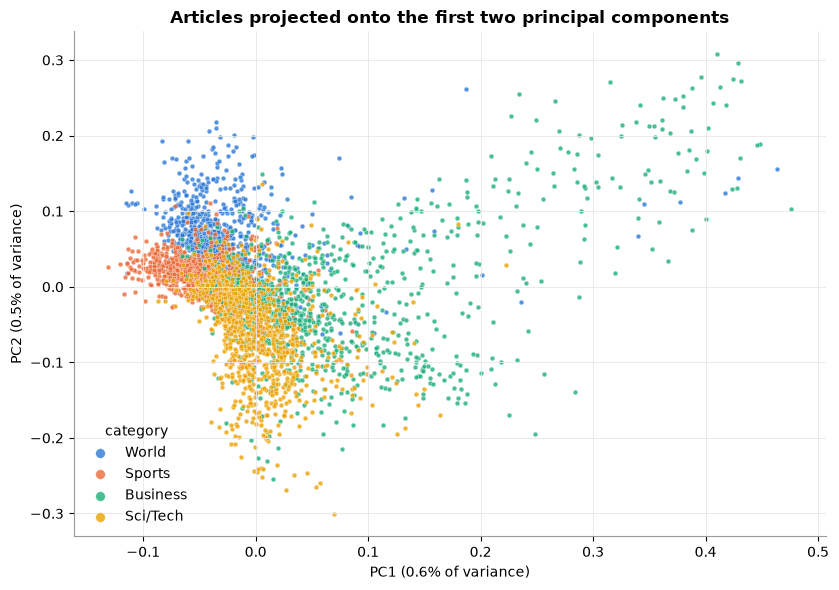

In [10]:
COLORS = {"World": "#2a78d6", "Sports": "#eb6834", "Business": "#1baf7a", "Sci/Tech": "#eda100"}

fig, ax = plt.subplots(figsize=(8.5, 6))
for cat in CLASSES:
    m = labels == cat
    ax.scatter(Z[m, 0], Z[m, 1], s=12, color=COLORS[cat], edgecolor="white", linewidth=0.3, alpha=0.8, label=cat)
ax.set(xlabel=f"PC1 ({explained[0]:.1%} of variance)", ylabel=f"PC2 ({explained[1]:.1%} of variance)",
       title="Articles projected onto the first two principal components")
ax.legend(title="category", frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

### Top words per component

In [11]:
rows = {}
for j in range(5):
    v = pd.Series(W[:, j], index=vocab)
    rows[f"PC{j + 1} (+)"] = ", ".join(v.nlargest(8).index)
    rows[f"PC{j + 1} (−)"] = ", ".join(v.nsmallest(8).index)
pd.Series(rows, name="largest weights").to_frame()

,largest weights
PC1 (+),"oil, prices, stocks, new, york, usa, profit, percent"
PC1 (−),"two, game, victory, night, win, saturday, first, season"
PC2 (+),"oil, iraq, us, prices, crude, minister, stocks, usa"
PC2 (−),"microsoft, software, inc, company, new, corp, mobile, million"
PC3 (+),"game, new, sox, first, red, york, night, victory"
PC3 (−),"iraq, microsoft, us, security, says, government, minister, software"
PC4 (+),"profit, quarter, percent, third, year, million, sales, inc"
PC4 (−),"new, microsoft, oil, york, windows, security, prices, search"
PC5 (+),"new, york, iraq, profit, usa, yankees, percent, killed"
PC5 (−),"microsoft, oil, world, prices, us, software, windows, cup"


### Word embeddings

Each word's row of $W$, scaled by $\sqrt{\lambda}$, is a 100-dimensional word vector. Nearest neighbours by cosine similarity:

In [12]:
word_emb = W * np.sqrt(eigvals[:K])
word_emb /= np.linalg.norm(word_emb, axis=1, keepdims=True)
word_index = {w: j for j, w in enumerate(vocab)}


def neighbours(word, top=8):
    sims = word_emb @ word_emb[word_index[word]]
    best = np.argsort(sims)[::-1][1:top + 1]
    return ", ".join(f"{vocab[j]} ({sims[j]:.2f})" for j in best)


query = ["oil", "game", "microsoft", "iraq", "election", "space", "stocks", "drug"]
pd.Series({w: neighbours(w) for w in query if w in word_index}, name="nearest words").to_frame()

,nearest words
oil,"barrel (0.92), prices (0.91), crude (0.91), winter (0.88), heating (0.88), supply (0.83), worries (0.83), supplies (0.82)"
game,"video (0.75), halo (0.63), summary (0.62), preseason (0.59), missed (0.58), losing (0.52), chiefs (0.49), houston (0.47)"
microsoft,"msn (0.65), windows (0.61), antitrust (0.57), xp (0.57), gates (0.56), targeting (0.54), code (0.53), pack (0.49)"
iraq,"iraqis (0.77), pentagon (0.74), kidnapped (0.70), iraqi (0.66), saddam (0.65), baghdad (0.65), insurgents (0.64), falluja (0.64)"
election,"voting (0.83), vote (0.82), polls (0.81), presidential (0.81), votes (0.80), hamid (0.70), karzai (0.70), voters (0.66)"
space,"shuttle (0.89), mission (0.85), crew (0.83), orbit (0.82), station (0.82), flight (0.78), nasa (0.74), utah (0.69)"
stocks,"climb (0.81), higher (0.81), investors (0.76), gains (0.64), sector (0.62), boosted (0.59), drop (0.59), watch (0.59)"
drug,"patients (0.86), vioxx (0.79), drugs (0.79), cancer (0.78), heart (0.74), merck (0.72), food (0.70), risk (0.57)"


## Summary of results

* **Variance.** Short news snippets give sparse TF-IDF vectors, so the variance is spread over many components. The first component explains 0.6%, 100 components keep 22%, and 349 / 863 / 1,183 components keep 50% / 80% / 90%.
* **Components.** The top components line up with the news categories: PC1 is business (*oil, prices, stocks*) against sports (*game, victory, season*), and PC2 is world news (*iraq, minister*) against tech (*microsoft, software*). In the 2-D plot, Business and Sci/Tech spread out along their own directions, while World and Sports overlap more in these first two dimensions.
* **Word embeddings.** Most nearest neighbours are meaningful: *oil* → barrel, crude; *space* → shuttle, orbit, nasa; *election* → voting, polls; *drug* → patients, vioxx. Some show the time period and source of the corpus (2004 news): *game* → video, halo, and *election* → karzai.